In [2]:
import numpy as np
import pandas as pd 
import os

In [3]:
# CIFAR10 dataset download1
from tensorflow.keras.datasets import cifar10

(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

print("train dataset shape:", train_images.shape, train_labels.shape)
print("test dataset shape:", test_images.shape, test_labels.shape)

train dataset shape: (50000, 32, 32, 3) (50000, 1)
test dataset shape: (10000, 32, 32, 3) (10000, 1)


In [4]:
train_images[0, :, :, :], train_labels[0, :]

(array([[[ 59,  62,  63],
         [ 43,  46,  45],
         [ 50,  48,  43],
         ...,
         [158, 132, 108],
         [152, 125, 102],
         [148, 124, 103]],
 
        [[ 16,  20,  20],
         [  0,   0,   0],
         [ 18,   8,   0],
         ...,
         [123,  88,  55],
         [119,  83,  50],
         [122,  87,  57]],
 
        [[ 25,  24,  21],
         [ 16,   7,   0],
         [ 49,  27,   8],
         ...,
         [118,  84,  50],
         [120,  84,  50],
         [109,  73,  42]],
 
        ...,
 
        [[208, 170,  96],
         [201, 153,  34],
         [198, 161,  26],
         ...,
         [160, 133,  70],
         [ 56,  31,   7],
         [ 53,  34,  20]],
 
        [[180, 139,  96],
         [173, 123,  42],
         [186, 144,  30],
         ...,
         [184, 148,  94],
         [ 97,  62,  34],
         [ 83,  53,  34]],
 
        [[177, 144, 116],
         [168, 129,  94],
         [179, 142,  87],
         ...,
         [216, 184, 140],
  

In [5]:
NAMES = np.array(['airplane', 'automobile', 'bird', 'cat', 'deer',
                    'dog', 'frog', 'horse', 'ship', 'truck'])
print(train_labels)

[[6]
 [9]
 [9]
 ...
 [9]
 [1]
 [1]]


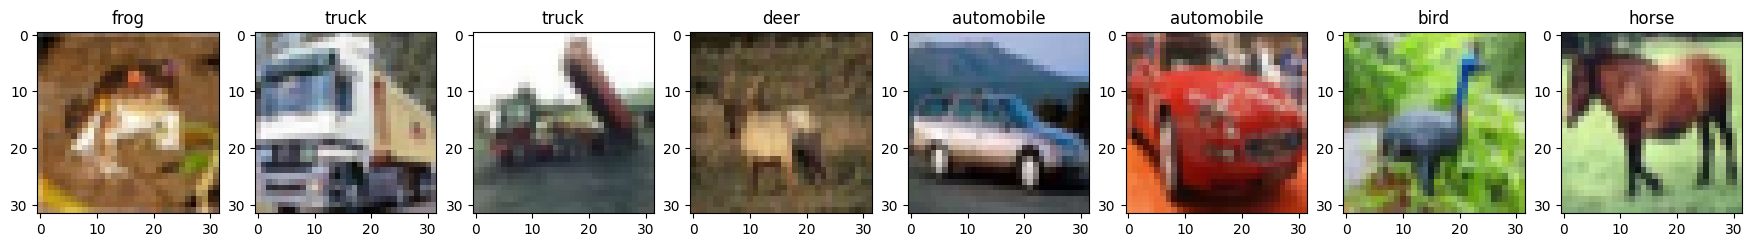

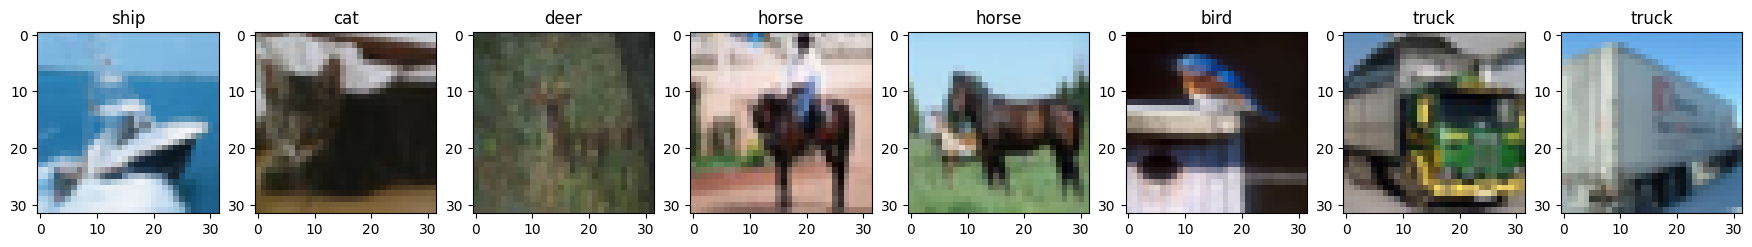

In [6]:
# CIFAR 데이터 시각화
import matplotlib.pyplot as plt
import cv2
%matplotlib inline

def show_images(images, labels, ncols=8):
    # figure: 그림 전체의 틀, axs: 개별 그림 
    figure, axs = plt.subplots(figsize=(22, 6), nrows=1, ncols=ncols)
    for i in range(ncols):
        axs[i].imshow(images[i])
        label = labels[i].squeeze()
        axs[i].set_title(NAMES[int(label)])

show_images(train_images[:8], train_labels[:8], ncols=8)
show_images(train_images[8:16], train_labels[8:16], ncols=8)

In [7]:
# data preprocessing
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

def get_preprocessed_data(images, labels):
    images = np.array(images/255.0, dtype=np.float32)
    labels = np.array(labels, dtype=np.int64)
    return images, labels

train_images, train_labels = get_preprocessed_data(train_images, train_labels)
test_images, test_labels = get_preprocessed_data(test_images, test_labels)

In [8]:
train_images[0, :, :, :]

array([[[0.23137255, 0.24313726, 0.24705882],
        [0.16862746, 0.18039216, 0.1764706 ],
        [0.19607843, 0.1882353 , 0.16862746],
        ...,
        [0.61960787, 0.5176471 , 0.42352942],
        [0.59607846, 0.49019608, 0.4       ],
        [0.5803922 , 0.4862745 , 0.40392157]],

       [[0.0627451 , 0.07843138, 0.07843138],
        [0.        , 0.        , 0.        ],
        [0.07058824, 0.03137255, 0.        ],
        ...,
        [0.48235294, 0.34509805, 0.21568628],
        [0.46666667, 0.3254902 , 0.19607843],
        [0.47843137, 0.34117648, 0.22352941]],

       [[0.09803922, 0.09411765, 0.08235294],
        [0.0627451 , 0.02745098, 0.        ],
        [0.19215687, 0.10588235, 0.03137255],
        ...,
        [0.4627451 , 0.32941177, 0.19607843],
        [0.47058824, 0.32941177, 0.19607843],
        [0.42745098, 0.28627452, 0.16470589]],

       ...,

       [[0.8156863 , 0.6666667 , 0.3764706 ],
        [0.7882353 , 0.6       , 0.13333334],
        [0.7764706 , 0

In [9]:
print(train_images.shape, train_labels.shape)

(50000, 32, 32, 3) (50000, 1)


In [10]:
# 2차원 lables 데이터를 1차원으로 변경
train_labels = train_labels.squeeze()
test_labels = test_labels.squeeze()

### Custom Model의 생성
- CNN Mdel의 맨 처음 layer는 <br>
 input layer, input layer.shape를 ImageSize와 RGB 3채널에 맞게 (32, 32, 3)으로 설정.</br>
- Conv2 연산을 연달아 적용하고 MaxPooling을 적용하는 루틴으로 모델 생성.
- Maxpooling 적용 후에는 필터 갯수를 더욱 증가시킴.
- Cifar10의 label수가 10개이므로,<br>
classification을 위한 맨 마지막 dense layer의 units의 개수는 10개임.</br>

In [11]:
IMAGE_SIZE = 32

In [12]:
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Conv2D, Dropout, Flatten, Activation, MaxPooling2D, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint, LearningRateScheduler

input_tensor = Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

# x = Conv2D(filters=32, kernel_size=(5, 5), padding='valid', activation='relu')(input_tensor)
x = Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu')(input_tensor)
x = Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu')(x)
x = MaxPooling2D(pool_size=(2,2))(x)

x = Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='relu')(x)
x = Conv2D(filters=64, kernel_size=(3, 3), padding='same')(x)
x = Activation('relu')(x)
x = MaxPooling2D(pool_size=2)(x) 

x = Conv2D(filters=128, kernel_size=(3, 3), padding="same", activation='relu')(x)
x = Conv2D(filters=128, kernel_size=(3, 3), padding="same", activation='relu')(x)
x = MaxPooling2D(pool_size=2)(x)

# cifar10의 클래스가 10개 이므로 마지막 classification의 dense layer의 units 갯수는 10
x = Flatten(name='flatten')(x)
x = Dropout(rate=0.5)(x)
x = Dense(300, activation='relu', name='fc1')(x)
x = Dropout(rate=0.3)(x)
output = Dense(10, activation='softmax', name='output')(x)

model = Model(inputs=input_tensor, outputs=output)

model.summary()

I0000 00:00:1792909106.857203    1588 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792909106.859317    1588 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 300)            │       614,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         3,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 904,718 (3.45 MB)

 Trainable params: 904,718 (3.45 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(optimizer=Adam(), 
             loss="sparse_categorical_crossentropy", 
             metrics=["accuracy"])

In [ ]:
'''
모델 학습 수행 및 테스트 데이터로 평가

Model의 fit() 메소드를 호출하여 학습
fit() 메소드는 학습 데이터가 np.array의 형태와, 
generator 형채로 들어올 때 수행로직의 차이가 존재한다.
model.fit( x = train_image_data,
           y = train_label_data,
           batch_size = 가져올 image/array의 갯수.
                        1개씩 가져오면 속도가 너무 느리고,
                        전체를 가져오면 gpu memory 부족이 발생할 수 있으므로
                        적절한 batch_size 설정이 필요함.
          epochs= (전체 학습 데이터의)학습을 반복할 횟수,
          steps_per_epoch = 전체 학습 데이터를 몇 번의 배치 작업으로 수행하는가를 의미,
          validation_data = 검증용 데이터 세트,
          validation_steps = 검증용 데이터의 steps_per_epoch,
          validation_split = 검증용 데이터로 별도의 데이터 세트를 실행하지 않고
                             자동으로 학습용 데이터에서 검증용 데이터 세트를 분할)
'''

In [14]:
history = model.fit(x=train_images,
                    y=train_labels,
                    batch_size=64,
                    epochs=30,
                    validation_split=0.15)

Epoch 1/30
 16/665 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.0973 - loss: 2.3052 

I0000 00:00:1792909128.286325    1652 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


665/665 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.3734 - loss: 1.6727 - val_accuracy: 0.5199 - val_loss: 1.3254
Epoch 2/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5701 - loss: 1.1980 - val_accuracy: 0.6223 - val_loss: 1.0959
Epoch 3/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6505 - loss: 0.9863 - val_accuracy: 0.6829 - val_loss: 0.9052
Epoch 4/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6992 - loss: 0.8567 - val_accuracy: 0.7273 - val_loss: 0.7841
Epoch 5/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7278 - loss: 0.7710 - val_accuracy: 0.7427 - val_loss: 0.7268
Epoch 6/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7510 - loss: 0.7054 - val_accuracy: 0.7515 - val_loss: 0.7002
Epoch 7/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7736 - loss: 0.6501 - val_accuracy: 0.7669 - val_loss: 0.6793
Epoch 8/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7896 - loss: 0.6011 - val_accuracy: 0.7753 - va

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7902 - loss: 0.7460


[0.7460184693336487, 0.7901999950408936]

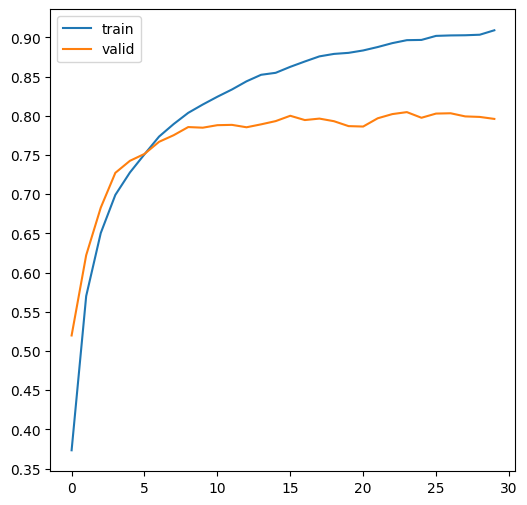

In [15]:
import matplotlib.pyplot as plt
%matplotlib inline

def show_history(history):
    plt.figure(figsize=(6, 6))
    plt.yticks(np.arange(0, 1, 0.05))
    plt.plot(history.history['accuracy'], label='train')
    plt.plot(history.history['val_accuracy'], label='valid')
    plt.legend()

show_history(history)

model.evaluate(test_images, test_labels)

# model.predict()를 통해 이미지 분류 예측
- 4차원 이미지의 배열을 입력해서 모델학습함, predict() 시에도 4차원 이미지 배열을 입력해야 함.
- 학습 데이터의 원-핫 인코딩 적용 여부와 관계없이 softmax 적용결과는 무조건 2차원 임에 유의

In [17]:
preds = model.predict(np.expand_dims(test_images[0], axis=0))
print('예측 결과 shape:', preds.shape)
print('예측 결과:', preds)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 844ms/step
예측 결과 shape: (1, 10)
예측 결과: [[1.0391998e-04 1.0851934e-06 2.3403969e-04 8.6257267e-01 8.9834739e-06
  1.3609500e-01 6.9168519e-04 9.5155419e-06 2.8230873e-04 8.2641844e-07]]


In [18]:
preds = model.predict(test_images[:32], batch_size=32)
print('예측 결과 shape:', preds.shape)
print('예측 결과:', preds)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step
예측 결과 shape: (32, 10)
예측 결과: [[1.03919403e-04 1.08518952e-06 2.34038860e-04 8.62572849e-01
  8.98344115e-06 1.36094838e-01 6.91683032e-04 9.51549828e-06
  2.82308232e-04 8.26417761e-07]
 [1.34033992e-10 1.94047425e-05 2.52697247e-20 1.34074686e-17
  2.34059155e-20 4.21768970e-25 3.83929926e-17 1.56792968e-23
  9.99980569e-01 8.76900982e-12]
 [1.50451273e-01 2.17009932e-01 6.94635557e-03 1.92430150e-02
  1.32697739e-03 4.52817604e-03 6.50772918e-03 2.16507143e-03
  5.74108005e-01 1.77135505e-02]
 [9.27049875e-01 2.37077149e-03 5.21811321e-02 1.19659561e-03
  1.11185736e-03 2.05119839e-04 1.78244867e-04 1.54979134e-04
  1.47218164e-02 8.29678436e-04]
 [2.14733897e-09 7.70472630e-10 2.87276460e-03 5.56539162e-04
  4.59757357e-05 2.57346358e-08 9.96524632e-01 1.61022168e-10
  6.18470564e-09 3.11145509e-09]
 [1.84737564e-06 1.52080077e-07 1.47859228e-03 8.87463167e-02
  1.82288568e-02 3.00048161e-02 8.61415029e-01 6.95720155e-05
  3.68620476e-06 5.1003

In [19]:
predicted_class = np.argmax(preds, axis=1)
print('예측 클래스 값:', predicted_class)

예측 클래스 값: [3 8 8 0 6 6 1 2 3 1 0 9 5 7 9 6 5 7 8 6 7 0 4 9 4 3 7 0 9 6 6 5]


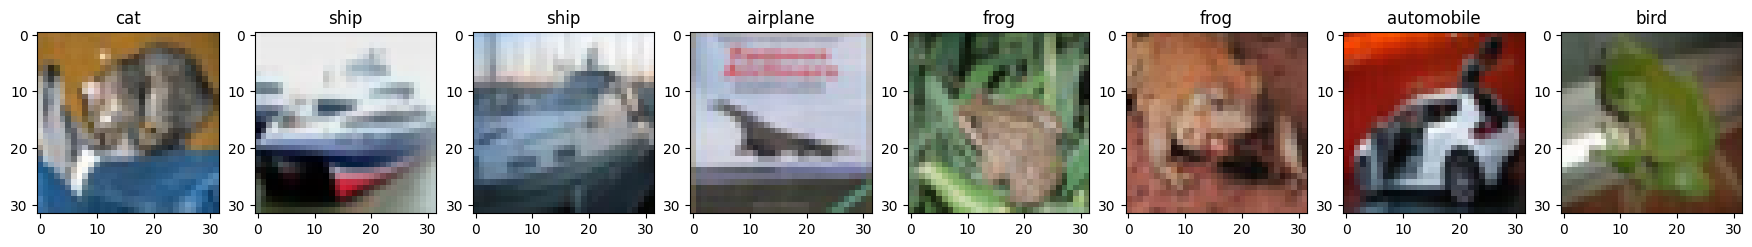

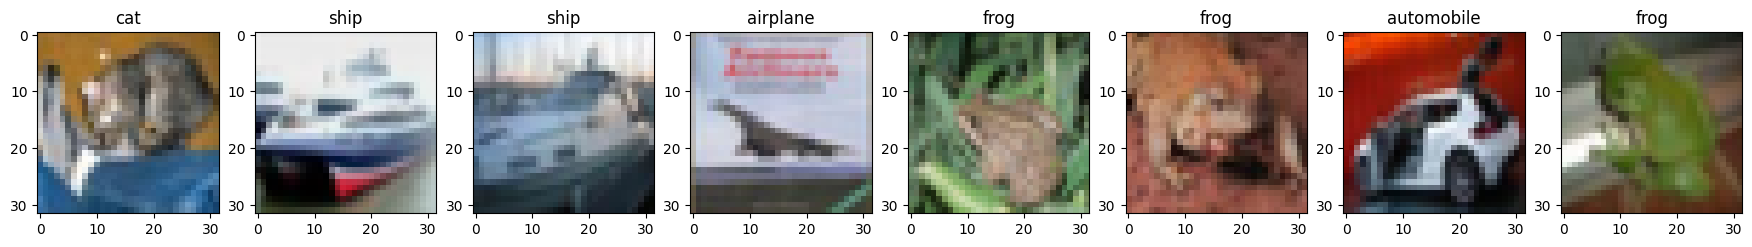

In [20]:
show_images(test_images[:8], predicted_class[:8], ncols=8)
show_images(test_images[:8], test_labels[:8], ncols=8)

## (번외) 가중치 초기화(Weight Initialization)의 이해와 적용
- 가중치 초기화는 딥러닝 모델의 학습 속도와 성능에 큰 영향을 미친다. 
- 잘못된 초기화는 활성화 함수에 의해 데이터 분포가 한쪽으로 쏠리거나, 전역 최솟값(local minima)에 도달하는 데 어려움을 겪게 할 수 있다. 
- 특히, 층이 깊어질수록 데이터가 활성화 함수를 거치며 왜곡되기 때문에 가중치 초기화는 필수적인 과정이다.

출처: yijoon009닝믜 티스토리 블로그 글을 참고했습니다.<br>
https://yijoon009.tistory.com/entry/weight-initialization-Xavier-initialization-He-initialization

### 좋은 **가중치 초기화** 조건
- **값이 동일해서는 안됨.**
- **충분히 작아야한다.**
- **적당한 분산, 표준 적용** 

In [21]:
# 평균이 1이고 표준편차가 1인 표준정규분포에서의 난수 추출
# 표준 편차가 클수록, 개별 값의 크기가 일반적으로 커짐
import numpy as np

# np.random.normal() - 표준 정규분포에서의 난수 추출
numbers = np.random.normal(loc=0.0, # location=0.0, (평균이 어디에 위치하는지, 여기서는 평균이 0이다)
                           scale=0.01, # 표준편차=0.01, 여기에서 표준편차의 의미는 스케일로 대체할 수 있다.
                           size=(100, 100))  # 

print(numbers)
print(numbers.mean()) 
print(numbers.std())  # standard deviation
print(numbers.sum())

[[ 0.00353944  0.00195387 -0.00201296 ... -0.01647254  0.0070705
  -0.00788595]
 [ 0.02078389  0.0049168  -0.0064432  ...  0.00767327 -0.00082598
   0.00679843]
 [-0.00018602  0.00075843 -0.00010989 ... -0.0074625  -0.00323036
   0.00189563]
 ...
 [-0.01978857 -0.0105933   0.01084004 ...  0.01479892 -0.00088412
  -0.0023787 ]
 [-0.00688749 -0.00956462 -0.01788276 ...  0.01473004  0.01271001
   0.0031482 ]
 [-0.00729302 -0.0069362  -0.00107699 ... -0.00604845 -0.00535717
  -0.00587946]]
0.00027220172062160744
0.009868615010146006
2.722017206216074


### **표준편차 변경**에 따른 **sigmoid 출력** 결과
- 표준 정규분포(mean= 0, **std= 1**)에서 가중치 초기화 시 : sigmoid 출력이 대부분 **0 ~ 1** 사이로 수렴
- 표준 정규분포(mean= 0, **std= 0.01**)에서 가중치 초기화 시 : sigmoid 출력이 대부분 **0**으로 수렴한다

## 가중치 초기화 기법 소개

### (1) Xavier Glorot Initialization
 자비에르(Glorot/ Xavier) 초기화 <br>
: 신경망이 깊어질수록 역전파(BackPropagation)과정에서 </br>
  **신호(기울기)가 너무 작아지거나, 폭발하는 현상** 을 막기 위해(gradient vanishing/exploding) <br>
  **입력노드와 출력노드의 개수**(fan in, fan out)를 동시에 고려하여 **가중치의 초기 분산을 동적으로 조절**한다.</br>

#### Glorot Uniform()과 Glorot Normal() 메소드
: 두 메소드 모두 가중치를 무작위로 생성하되, 그 분포의 폭(범위 or 표준편차)를 fan_in과 fan_out기반으로 다르게 설정한다.

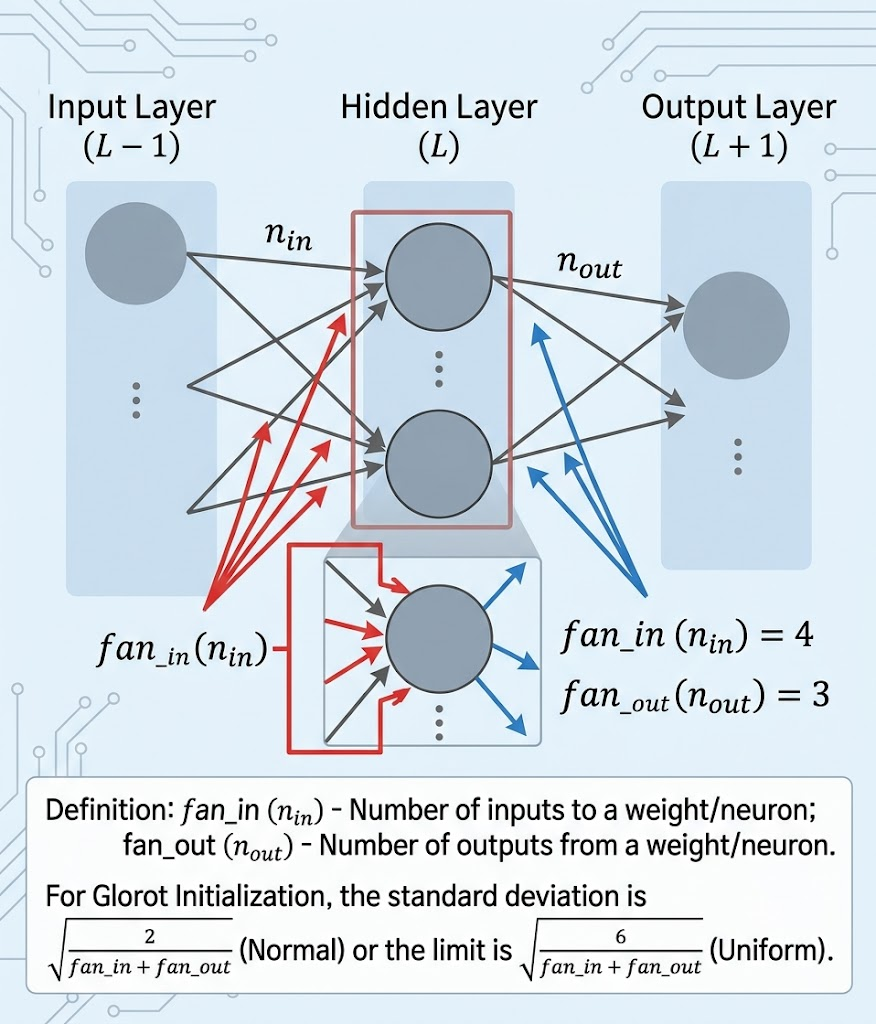

### (1) Glorot Uniform(); 균일분포 <br>
    Uniform Ditribution( -threds, +threds )를 따르는 난수로 가중치를 초기화한다. <br>
    (-한도값) ~ (+한도값) 사이의 균등한 확률로 값을 뽑아낸다.<br>
    - 한도값(limit):

### (2) Glorot Normal(); 정규분포 <br>
    Normal Distribution(mean=0, std); 정규분포를 따르는 난수로 가중치를 초기화한다. <br>
    평균이 0이고, 아래의 표준편차를 갖는 정규분포 곡선에서 값을 무작위로 추출한다. </br>
    - 표준편차(standard deviation):

### parameters
- fan_in + fan_out <br>
    : 이전 층의 크기와 다음 층의 크기를 모두 반영하여,<br>
    레이어가 넓어지거나 좁아질 때 가중치 분산이 적절하게 스케일링되도록 잡아주는 역할을 한다.  <br>

- 분자(위에 있는 수식)에 있는 6(glorot_uniform)과 2(glorot_normal) <br>
    : 균등 분포와 정규 분포 각각의 수학적 분산 공식을 유도하는 과정에서 파생된 스케일 상수이다. <br>
    예를 들어, 균등 분포의 폭 공식( (3 x variance) xx 0.5 )과 결합될 때 <br>
    분모의 2와 곱해져서 6이라는 숫자가 도출되게 된다.<br>


In [ ]:
# Xavier Initializaion : 정규분포(glorot_normal)와 균일분포(glorot_uniform)

In [22]:
# glorot_normal
fan_in = 10
fan_out = 8
scale_value = np.sqrt(2/(fan_in + fan_out))
print('scale:', scale_value)

weights = np.random.normal(loc=0.0, scale=scale_value, size=(100, 100))
print(weights)
print('weights mean:', weights.mean(), 'std:', weights.std(), 'sum:', weights.sum())


scale: 0.3333333333333333
[[ 0.1164926   0.12426969  0.31176302 ... -0.23998015  0.00226231
   0.38718573]
 [ 0.43012161  0.05073979 -0.12358496 ...  0.44937364  0.1773868
   0.34519568]
 [-0.09740428 -0.26133964  0.31909166 ...  0.12009608 -0.0128121
   0.17407853]
 ...
 [-0.65904316 -0.34078177 -0.16582955 ...  0.28620032 -0.22661031
   0.05004252]
 [ 0.18213264 -0.05699599 -0.71330646 ... -0.32044016  0.55593627
  -0.24737173]
 [ 0.14973509  0.33765902  0.06472184 ...  0.26947328  0.52975413
  -0.23429809]]
weights mean: -0.0018291195427649245 std: 0.3282759774686612 sum: -18.291195427649246


In [24]:
# glorot_uniform
fan_in = 10
fan_out = 8
limit = np.sqrt(6/(fan_in + fan_out))
print('limit:', limit)

weights = np.random.uniform(-1 * limit, limit, size=(100, 100)) # -limit, limit 를 표현.
print(weights)
print('weights mean:', weights.mean(), 'std:', weights.std(), 'sum:', weights.sum())

limit: 0.5773502691896257
[[-0.10196119 -0.43299055 -0.56945426 ... -0.00128031  0.05077031
  -0.08234058]
 [-0.49646711  0.46693684 -0.56405381 ...  0.5426679   0.1255451
   0.48816819]
 [-0.16298264 -0.07352135 -0.35200291 ...  0.08973005  0.43044502
  -0.35565396]
 ...
 [ 0.02140822  0.43108665  0.51853222 ... -0.45014377 -0.49287909
   0.45668579]
 [ 0.53177769  0.53737814 -0.53095647 ...  0.31713555 -0.20227816
   0.13613622]
 [ 0.3816759  -0.43857199 -0.27862345 ... -0.1909714   0.2857057
  -0.55552564]]
weights mean: -0.0010665314036880837 std: 0.3310619633929355 sum: -10.665314036880837


### Xavier 초기화의 한계<br>
: 시그모이드와 같은 활성화함수에서는 좋은 성과를 냈지만, ReLU 함수와 결합했을 때는 문제가 발생한다.</br>
ReLU(입력값이 양수일때 미분값이 1)과 Xavier 초기화를 함께 사용하면, relu의 특성 때문에 출력값이 불안정해진다.<br>
(relu는 음수 값을 모두 0으로 만들어 버리는 특성이 있다.) 

In [ ]:
# Python 코드로 구현한 Xavier 초기화 
'''
class Net:
    def _init_(self,

    # (중략)
    def _init_weight(self, weight_init_std):
        # 전체 네트워크의 각 층의 뉴런 수를 리스트로 구성
        all_size_list = [self.input_sizel + self.hidden_size_list + [self.output_size]

        # 모든 층을 순회하며 가중치를 초기화
        for idx in range(1, len(all_size_list)):
            scale = weight_init_std

            # ReLU 활성화 함수들 사용할 경우 He 초기화 방법 사용
            if str(weight_init_std). lower() in ('relu', 'he'):
                scale = np.sart(2.0 / all_size_list[idx - 1])

            # Sigmold 활성화 함수를 사용할 경우 Xavier 초기화 방법 사용
            elif str(weight_init_std). lower() in ('sigmoid', 'xavier'):
                scale = np.sqrt(1.0 / all_size_list[idx - 1])

            # 가중지와 편향 조기화
            self-params[f'W{idx}'] = scale * np. random.randn(all_size_list[idx-1], all_size_list[idx])
            self-params[f'b{idx}'] = np.zeros(all_size_list[idx])
'''

### (2) He Initialization - ReLU에 보다 최적화된 가중치 초기화 기법
위의 문제를 해결하기 위해 등장한 기법으로, <br>
자비에르 초기화 비슷하지만 ReLU의 특성에 맞게 가중치를 초기화한다.<br>
He 초기화는 Xavier 초기화보다 더 큰 표준편차를 설정하여 **2/n**을 사용한다.<br>
이는 relu 함수의 특성에 적합하며, 출력의 불안정성을 완화시켜 준다.

#### he_uniform()와 he_normal() 메소드

### (1) he_uniform() <br>
    Uniform Ditribution(-threds, +threds)

### (2) he_normal <br>
    Normal Distribution(mean=0, std)


In [ ]:
# He Initialization - 정규분포(he_normal), 균일분포(he_uniform)

In [ ]:
# Python 코드로 구현한 He 초기화
'''
class Net:
    def _init_(self,

    # (중략)

    def _init_weight(self, weight_init_std):
        # 전체 네트워크의 각 층의 뉴런 수를 리스트로 구성
        all_size_list = [self.input_sizel + self.hidden_size_list + [self.output_size]

        # 모든 층을 순회하며 가중치를 초기화
        for idx in range(1, len(all_size_list)):
            scale = weight_init_std

            # ReLU 활성화 함수들 사용할 경우 He 초기화 방법 사용
            if str(weight_init_std). lower() in ('relu', 'he'):
                scale = np.sart(2.0 / all_size_list[idx - 1])

            # Sigmold 활성화 함수를 사용할 경우 Xavier 초기화 방법 사용
            elif str(weight_init_std). lower() in ('sigmoid', 'xavier'):
                scale = np.sqrt(1.0 / all_size_list[idx - 1])

            # 가중지와 편향 조기화
            self-params[f'W{idx}'] = scale * np. random.randn(all_size_list[idx-1], all_size_list[idx])
            self-params[f'b{idx}'] = np.zeros(all_size_list[idx])
'''

(결론)<br>
가중치 초기화를 선택할 때, 결국 어떤 활성화 함수를 선택하느냐에 달려있다.<br>
그러나 위 방법이 또 무조건 맞다고는 못하기 때문에 다양한 방법을 시도해 보는 것이 중요하다.


가중치 초기화를 He Normal로 변경 후 성능 검증
- tf.keras의 conv2d의 기본 weight 초기화는 glorot_uniform.
- 이를 he_normal로 변경 후 동일 모델의 성능 테스트
- label은 원-핫 인코딩 적용함

In [25]:
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical


def get_preprocessed_data(images, labels):
    images = np.array(images / 255.0, dtype=np.float32)
    labels = np.array(labels, dtype=np.int64) # int64로 수정
    return images, labels

def get_preprocessed_ohe(images, labels):
    images, labels = get_preprocessed_data(images, labels)
    oh_labels = to_categorical(labels)
    return images, oh_labels

(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()
train_images, train_oh_labels = get_preprocessed_ohe(train_images, train_labels)
test_images, test_oh_labels = get_preprocessed_ohe(test_images, test_labels)

print(train_images.shape, train_oh_labels.shape, test_images.shape, test_oh_labels.shape)

(50000, 32, 32, 3) (50000, 10) (10000, 32, 32, 3) (10000, 10)


In [26]:
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Conv2D, Dropout, Flatten, Activation, MaxPooling2D, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint, LearningRateScheduler

input_tensor = Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

# x = Conv2D(filters=32, kernel_size=(5, 5), padding='valid', activation='relu')(input_tensor)
x = Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu', kernel_initializer='he_normal')(input_tensor)
x = Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu', kernel_initializer='he_normal')(x)
x = MaxPooling2D(pool_size=(2,2))(x)

x = Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='relu', kernel_initializer='he_normal')(x)
x = Conv2D(filters=64, kernel_size=(3, 3), padding='same', kernel_initializer='he_normal')(x)
x = Activation('relu')(x)
x = MaxPooling2D(pool_size=2)(x) 

x = Conv2D(filters=128, kernel_size=(3, 3), padding="same", activation='relu', kernel_initializer='he_normal')(x)
x = Conv2D(filters=128, kernel_size=(3, 3), padding="same", activation='relu', kernel_initializer='he_normal')(x)
x = MaxPooling2D(pool_size=2)(x)

# cifar10의 클래스가 10개 이므로 마지막 classification의 dense layer의 units 갯수는 10
x = Flatten(name='flatten')(x)
x = Dropout(rate=0.5)(x)
x = Dense(300, activation='relu',kernel_initializer='he_normal', name='fc1')(x)
x = Dropout(rate=0.3)(x)
output = Dense(10, activation='softmax', name='output')(x)

model = Model(inputs=input_tensor, outputs=output)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 300)            │       614,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         3,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 904,718 (3.45 MB)

 Trainable params: 904,718 (3.45 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
model.compile(optimizer=Adam(), 
             loss="categorical_crossentropy", 
             metrics=["accuracy"])

history = model.fit(x=train_images, y=train_oh_labels, 
                    batch_size=64,
                    epochs=30, validation_split=0.15)

Epoch 1/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.4254 - loss: 1.5592 - val_accuracy: 0.4983 - val_loss: 1.3848
Epoch 2/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6027 - loss: 1.1173 - val_accuracy: 0.6649 - val_loss: 0.9486
Epoch 3/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6733 - loss: 0.9238 - val_accuracy: 0.6557 - val_loss: 0.9934
Epoch 4/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7148 - loss: 0.8152 - val_accuracy: 0.7457 - val_loss: 0.7287
Epoch 5/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7513 - loss: 0.7084 - val_accuracy: 0.7536 - val_loss: 0.7011
Epoch 6/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7703 - loss: 0.6511 - val_accuracy: 0.7640 - val_loss: 0.6906
Epoch 7/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7928 - loss: 0.5925 - val_accuracy: 0.7621 - val_loss: 0.6838
Epoch 8/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8071 - loss: 0.5463 - val_accuracy: 

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7851 - loss: 0.7383


[0.738305926322937, 0.785099983215332]

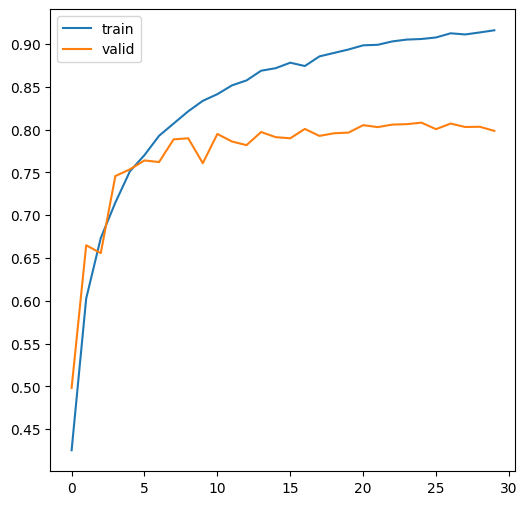

In [28]:
show_history(history)

model.evaluate(test_images, test_oh_labels)

### 배치 정규화(Batch Normalization)의 이해와 적용

### 학습 데이터 shuffle 적용 유무에 따른 모델 성능 비교

### 배치크기 변경에 따른 모델 성능 비교

### 학습율(learning rate)의 동적변경에 따른 모델 성능 비교

### 필터수와 층의 깊이 변경에 따른 모델 성능 비교

### Global Average Pooling의 이해와 적용

### 가중치 규제(Regularization)의 이해와 적용